In [1]:
!pip install -q gymnasium pandas numpy matplotlib

TD Prediction - State Values
 State  State Value
     0 1.021858e-05
     1 2.236575e-05
     2 1.753894e-05
     3 7.629087e-06
     4 3.451785e-06
     5 0.000000e+00
     6 1.940275e-06
     7 0.000000e+00
     8 3.473994e-07
     9 2.245599e-02
    10 1.996257e-04
    11 0.000000e+00
    12 0.000000e+00
    13 7.605859e-03
    14 8.506418e-01
    15 0.000000e+00

SARSA Q-Table
     Left   Down  Right     Up
0   0.001  0.008  0.002  0.003
1   0.000  0.000  0.000  0.004
2   0.000  0.000  0.062  0.000
3   0.000  0.000  0.000  0.000
4   0.016  0.000  0.000  0.000
5   0.000  0.000  0.000  0.000
6   0.000  0.000  0.024  0.000
7   0.000  0.000  0.000  0.000
8   0.000  0.001  0.003  0.011
9   0.003  0.199  0.022  0.012
10  0.002  0.002  0.002  0.004
11  0.000  0.000  0.000  0.000
12  0.000  0.000  0.000  0.000
13  0.079  0.027  0.711  0.063
14  0.120  0.972  0.143  0.033
15  0.000  0.000  0.000  0.000

Q-Learning Q-Table
     Left   Down  Right     Up
0   0.007  0.005  0.044  0.005
1   0.0

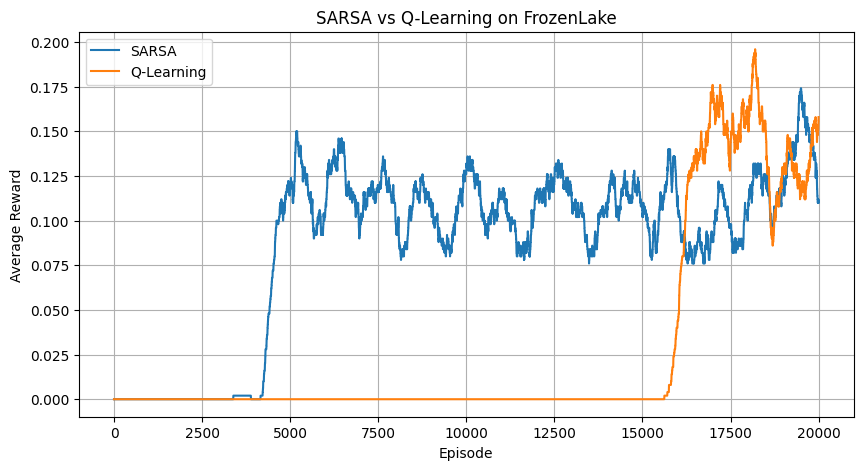


Best actions learned by SARSA:
['Down', 'Up', 'Right', 'Left', 'Left', 'Left', 'Right', 'Left', 'Up', 'Down', 'Up', 'Left', 'Left', 'Right', 'Down', 'Left']

Best actions learned by Q-Learning:
['Right', 'Up', 'Up', 'Up', 'Left', 'Left', 'Right', 'Left', 'Up', 'Down', 'Right', 'Left', 'Left', 'Right', 'Down', 'Left']


In [3]:

import gymnasium as gym
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

# Create FrozenLake environment
env = gym.make("FrozenLake-v1")

# Parameters
alpha = 0.85
gamma = 0.90
epsilon = 0.10
num_episodes = 20000
max_steps = 100

n_states = env.observation_space.n
n_actions = env.action_space.n

# ==========================================
# PART 1: TEMPORAL DIFFERENCE (TD) PREDICTION
# ==========================================

V = np.zeros(n_states)

for episode in range(num_episodes):
    state, _ = env.reset()

    for step in range(max_steps):
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, _ = env.step(action)

        # TD(0) update rule
        V[state] += alpha * (
            reward + gamma * V[next_state] - V[state]
        )

        state = next_state

        if terminated or truncated:
            break

td_df = pd.DataFrame({
    "State": range(n_states),
    "State Value": V
})

print("TD Prediction - State Values")
print(td_df.to_string(index=False))

# ==========================================
# PART 2: SARSA (ON-POLICY TD CONTROL)
# ==========================================

def epsilon_greedy(Q, state, epsilon):
    if random.random() < epsilon:
        return env.action_space.sample()
    return int(np.argmax(Q[state]))

Q_sarsa = np.zeros((n_states, n_actions))
sarsa_rewards = []

for episode in range(num_episodes):
    state, _ = env.reset()
    action = epsilon_greedy(Q_sarsa, state, epsilon)
    total_reward = 0

    for step in range(max_steps):
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        if done:
            target = reward
            Q_sarsa[state, action] += alpha * (
                target - Q_sarsa[state, action]
            )
            total_reward += reward
            break

        next_action = epsilon_greedy(
            Q_sarsa, next_state, epsilon
        )

        # SARSA update: Q(s,a) uses the next chosen action
        target = reward + gamma * Q_sarsa[next_state, next_action]
        Q_sarsa[state, action] += alpha * (
            target - Q_sarsa[state, action]
        )

        state = next_state
        action = next_action
        total_reward += reward

    sarsa_rewards.append(total_reward)

print("\nSARSA Q-Table")
print(pd.DataFrame(
    Q_sarsa,
    columns=["Left", "Down", "Right", "Up"]
).round(3))

# ==========================================
# PART 3: Q-LEARNING (OFF-POLICY TD CONTROL)
# ==========================================

Q_learning = np.zeros((n_states, n_actions))
q_rewards = []

for episode in range(num_episodes):
    state, _ = env.reset()
    total_reward = 0

    for step in range(max_steps):
        action = epsilon_greedy(
            Q_learning, state, epsilon
        )

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-Learning update uses the maximum next-state Q value
        target = reward + gamma * np.max(Q_learning[next_state])

        Q_learning[state, action] += alpha * (
            target - Q_learning[state, action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    q_rewards.append(total_reward)

print("\nQ-Learning Q-Table")
print(pd.DataFrame(
    Q_learning,
    columns=["Left", "Down", "Right", "Up"]
).round(3))

# ==========================================
# PART 4: COMPARE SARSA AND Q-LEARNING
# ==========================================

window = 500

sarsa_avg = pd.Series(sarsa_rewards).rolling(
    window, min_periods=1
).mean()

q_avg = pd.Series(q_rewards).rolling(
    window, min_periods=1
).mean()

plt.figure(figsize=(10, 5))
plt.plot(sarsa_avg, label="SARSA")
plt.plot(q_avg, label="Q-Learning")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("SARSA vs Q-Learning on FrozenLake")
plt.legend()
plt.grid(True)
plt.show()

# Display learned actions
action_names = ["Left", "Down", "Right", "Up"]

print("\nBest actions learned by SARSA:")
print([action_names[a] for a in np.argmax(Q_sarsa, axis=1)])

print("\nBest actions learned by Q-Learning:")
print([action_names[a] for a in np.argmax(Q_learning, axis=1)])

env.close()


Training completed!
Q-table shape: (500, 6)
Total states: 500
Total actions: 6
Average reward over last 100 episodes: 2.68


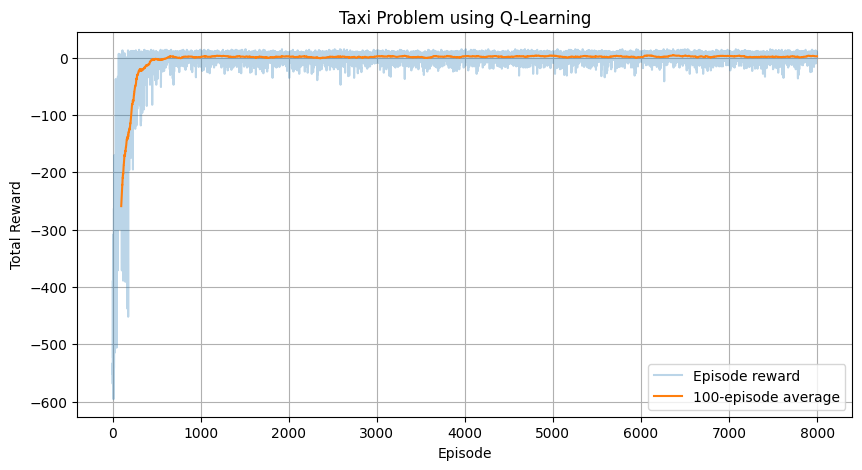

Test episode reward: 10


In [5]:

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create Taxi environment
env = gym.make("Taxi-v4")

# Initialize parameters
alpha = 0.4
gamma = 0.99
epsilon = 0.1
num_episodes = 8000
max_steps = 200

n_states = env.observation_space.n
n_actions = env.action_space.n

# Initialize Q-table
Q = np.zeros((n_states, n_actions))
episode_rewards = []

# Epsilon-greedy policy
def choose_action(state, epsilon):
    if np.random.random() < epsilon:
        return env.action_space.sample()
    return int(np.argmax(Q[state]))

# Q-Learning training
for episode in range(num_episodes):
    state, _ = env.reset()
    total_reward = 0

    for step in range(max_steps):
        action = choose_action(state, epsilon)

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Q-Learning update rule
        Q[state, action] += alpha * (
            reward
            + gamma * np.max(Q[next_state])
            - Q[state, action]
        )

        state = next_state
        total_reward += reward

        if done:
            break

    episode_rewards.append(total_reward)

# Display results
print("Training completed!")
print("Q-table shape:", Q.shape)
print("Total states:", n_states)
print("Total actions:", n_actions)
print("Average reward over last 100 episodes:",
      round(np.mean(episode_rewards[-100:]), 2))

# Plot learning progress
plt.figure(figsize=(10, 5))
plt.plot(episode_rewards, alpha=0.3, label="Episode reward")

rolling_rewards = np.convolve(
    episode_rewards,
    np.ones(100) / 100,
    mode="valid"
)

plt.plot(
    range(99, num_episodes),
    rolling_rewards,
    label="100-episode average"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Taxi Problem using Q-Learning")
plt.legend()
plt.grid(True)
plt.show()

# Test the trained agent
state, _ = env.reset()
total_reward = 0

for step in range(max_steps):
    action = int(np.argmax(Q[state]))
    state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward

    if terminated or truncated:
        break

print("Test episode reward:", total_reward)

env.close()
